# P3.11 — Sitting tenants and new tenants: the rent-update coefficient

**Questions:** RQ6.1 (have rent-control measures reduced rents for affected tenants?) and RQ6.3 (who benefits from rent regulation, and
who finds access harder?), in the one respect the data allow. Portugal does not cap the rent of a new lease; it caps the **yearly
rise of an existing one** by a coefficient INE publishes (CPI without housing, 12 months to August), and in 2023 by an extraordinary
ceiling of 2% in place of the formula's 5.43% (`data/external/rent_update_coefficients.csv`). Rent ceilings on new leases, their effect
on rental supply, maintenance and conversion (RQ6.2), and the leases themselves are not in the data.

**What is measured.** (1) For a lease signed at the median rent of new leases in 2020, the highest rent it can reach by 2024 under the
coefficients, against the median rent of new leases, the price level and the rent without the 2023 ceiling. (2) The same by
municipality (rents of new leases 2020 and 2024, `ine_median_rent_sqm`): the **gap** a new tenant pays above that sitting tenant. (3)
How much of the let stock this touches: new leases a year per 100 rented dwellings (census 2021). Accounting from rules and observed
rents, no behaviour.

**Reading rule, fixed before looking:** a "dual market" is read if the new-lease rent exceeds the updated old rent in most
municipalities (median gap above 10%) and the gap is not smaller where more homes are let. Whether it is *caused* by the update rule
is not tested: a gap would also open with no rule if rents rose faster than the CPI.

In [1]:
import pandas as pd

from pthousing.analysis import incidence as inc
from pthousing.analysis import rent_update as ru
from pthousing.analysis import supply
from pthousing.config import PROCESSED, RENTED_DWELLING_AREA_SQM
from pthousing.data import interim
from pthousing.viz import charts, style

style.apply_style()
BASE, LAST, CENSUS_YEAR, CEILING_YEAR = 2020, 2024, 2021, 2023
coef = ru.read()
style.save_table(
    coef[["legal_coefficient", "formula_coefficient"]].reset_index(),
    "p3",
    "rent_update_coefficients",
)
panel = pd.read_parquet(PROCESSED / "panel_municipality_year.parquet")
rent = panel.loc[
    panel["rent_sqm_eur"].notna(), ["muni_code", "year", "rent_sqm_eur", "new_leases_n"]
]
cpi = interim.read("ine_cpi").set_index("year")["cpi_index_b2025"]
ceiling = coef.loc[CEILING_YEAR]
print(coef.loc[BASE:LAST, ["legal_coefficient", "formula_coefficient"]])

      legal_coefficient  formula_coefficient
year                                        
2020             1.0051               1.0051
2021             0.9997               0.9997
2022             1.0043               1.0043
2023             1.0200               1.0543
2024             1.0694               1.0694


## Step 1 — What the coefficients allow, nationally
The median rent of new leases is the median over the municipalities that publish a rent in both 2020 and 2024 (a fixed set, so the
index does not move because more places publish), each weighted equally (a typical municipality, as in `p1_01`). Each rise applies
from the year after signing; a coefficient below one (2021) counts as no rise, since the update is optional.

In [2]:
nat_rent = ru.balanced_median(rent, BASE, LAST)
path = ru.national_path(coef, BASE, range(BASE, LAST + 1), nat_rent, cpi)
style.save_table(path.round(2).reset_index(), "p3", "rent_update_path")
print(path.round(1).to_string())
legal_rise = ru.allowed_rise_pct(coef, BASE, LAST, "legal_coefficient")
formula_rise = ru.allowed_rise_pct(coef, BASE, LAST, "formula_coefficient")
print(
    f"\nlease signed {BASE}: may rise {legal_rise:.1f}% to {LAST} ({formula_rise:.1f}% without the {CEILING_YEAR} ceiling); "
    f"CPI {path.loc[LAST, 'cpi_index'] - 100:.1f}%; median new lease {path.loc[LAST, 'new_lease_rent_index'] - 100:.1f}%"
)
real = 100 * (path.loc[LAST, "legal_rent_index"] / path.loc[LAST, "cpi_index"] - 1)
print(
    f"real rent of the sitting tenant {real:.1f}%; the ceiling cut the {CEILING_YEAR} rise from "
    f"{100 * (ceiling['formula_coefficient'] - 1):.2f}% to {100 * (ceiling['legal_coefficient'] - 1):.2f}%"
)

      legal_rent_index  formula_rent_index  new_lease_rent_index  cpi_index  new_over_legal_pct
year                                                                                           
2020             100.0               100.0                 100.0      100.0                 0.0
2021             100.0               100.0                 104.5      101.3                 4.5
2022             100.4               100.4                 115.9      109.2                15.4
2023             102.4               105.9                 131.7      113.9                28.6
2024             109.5               113.2                 146.9      116.7                34.1

lease signed 2020: may rise 9.5% to 2024 (13.2% without the 2023 ceiling); CPI 16.7%; median new lease 46.9%
real rent of the sitting tenant -6.1%; the ceiling cut the 2023 rise from 5.43% to 2.00%


## Step 2 — The gap by municipality
For each municipality with a rent of new leases in 2020 and in 2024, the 2024 median against the 2020 median raised by the legal
coefficients. The gap by third of 2024 price-to-income, and its link with the share of homes let. Turnover is the new leases of the
census year (2021) per 100 homes let in the census: same year for flow and stock.

In [3]:
cum = ru.cumulative(coef["legal_coefficient"], BASE + 1, LAST)
gap = ru.market_gap(rent, BASE, LAST, cum)
d = panel[panel["year"] == LAST].set_index("muni_code")
stock = supply.read_stock()
uses = inc.dwellings_by_use(stock, interim.read("ine_census"))
gap["rented_n"] = uses["rented"]
gap["dwellings_n"] = uses.sum(axis=1)
gap["rented_share_pct"] = 100 * gap["rented_n"] / gap["dwellings_n"]
gap["pti_years"] = d["pti_years"]
leases = rent[rent["year"] == CENSUS_YEAR].set_index("muni_code")["new_leases_n"]
gap["turnover"] = ru.turnover(leases.reindex(gap.index), gap["rented_n"])
pti_third = inc.terciles(
    gap["pti_years"], ("most affordable", "middle", "least affordable")
).rename("pti_third")
print(
    f"{len(gap)} municipalities; share with a positive gap {100 * (gap['gap_pct'] > 0).mean():.0f}%"
)
print(
    gap[["market_rise_pct", "gap_pct", "rented_share_pct", "turnover"]]
    .describe()
    .round(1)
    .to_string()
)

191 municipalities; share with a positive gap 98%
       market_rise_pct  gap_pct  rented_share_pct  turnover
count            191.0    191.0             191.0     187.0
mean              45.0     32.3              12.0      10.6
std               16.9     15.4               6.0       3.5
min                2.6     -6.3               2.0       3.3
25%               37.4     25.5               7.4       8.1
50%               44.6     32.0              10.8      10.1
75%               51.3     38.1              15.0      12.7
max              124.5    104.9              33.8      23.4


In [4]:
by_third = ru.gap_by_group(gap, pti_third)
style.save_table(by_third.round(2).reset_index(), "p3", "rent_update_gap_by_third")
print(by_third.round(1).to_string())
rho = ru.rank_correlations(gap, "gap_pct", ["rented_share_pct", "pti_years"])
print(f"rank correlation of the gap: {rho.round(2).to_dict()}")
print(
    f"turnover {gap['turnover'].median():.1f} new leases per 100 let homes in the median municipality "
    f"({len(gap['turnover'].dropna())} with both)"
)

                  municipalities_n  median_market_rise_pct  median_gap_pct  rented_share_pct  median_new_leases_per_100_rented
pti_third                                                                                                                     
most affordable                 64                    40.9            28.6               8.6                              11.5
middle                          63                    46.6            33.8              13.8                              10.4
least affordable                64                    45.8            33.1              20.0                               9.5
rank correlation of the gap: {'rented_share_pct': -0.04, 'pti_years': 0.24}
turnover 10.1 new leases per 100 let homes in the median municipality (187 with both)


## Step 3 — What the 2023 ceiling saved
In 2023 the formula would have allowed 5.43%, the law 2.00% (for leases signed before 2022). For a lease at the 2022 median rent
per m2 of its municipality, the monthly rent saved in 2023. The area of a let home is an assumption (`RENTED_DWELLING_AREA_SQM`,
70 m2; the census mean of all dwellings is larger), shown at 50 and 90 m2. The stock-wide figure assumes every let dwelling was
updated at the ceiling, so it is an upper bound.

In [5]:
r22 = rent[rent["year"] == CEILING_YEAR - 1].set_index("muni_code")["rent_sqm_eur"]
rented_total = float(uses["rented"].sum())
rows = []
for area in (50, RENTED_DWELLING_AREA_SQM, 90):
    saving = ru.ceiling_saving(
        r22, area, ceiling["legal_coefficient"], ceiling["formula_coefficient"]
    ).dropna()
    rows.append(
        ru.saving_summary(saving, rented_total).assign(area_sqm=area, municipalities_n=len(saving))
    )
sensitivity = pd.concat(rows, ignore_index=True)
style.save_table(sensitivity.round(2), "p3", "rent_ceiling_2023_saving")
print(sensitivity.round(1).to_string())

   median_rent_before_eur  saving_eur_month  saving_pct_of_rent  rented_dwellings_n  upper_bound_eur_m_year  area_sqm  municipalities_n
0                   214.0               7.3                 3.4            922810.0                    81.3        50               203
1                   299.6              10.3                 3.4            922810.0                   113.8        70               203
2                   385.2              13.2                 3.4            922810.0                   146.3        90               203


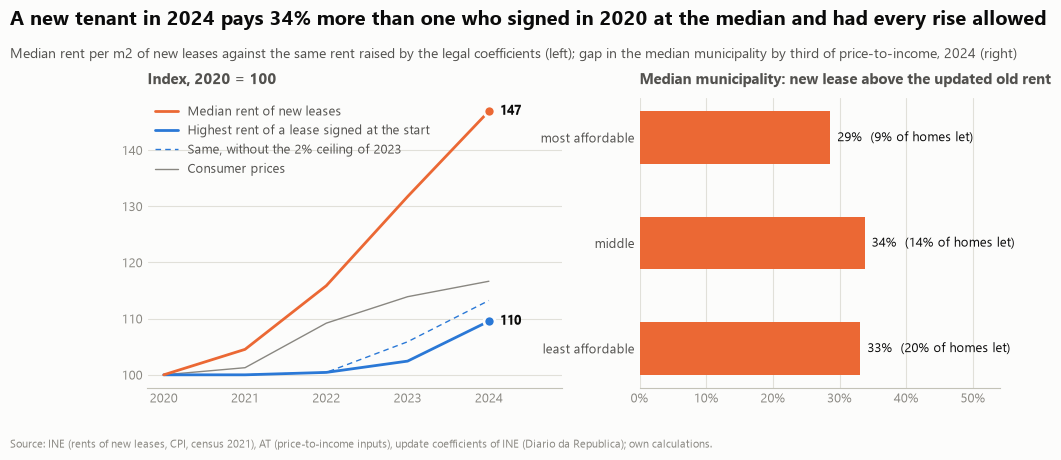

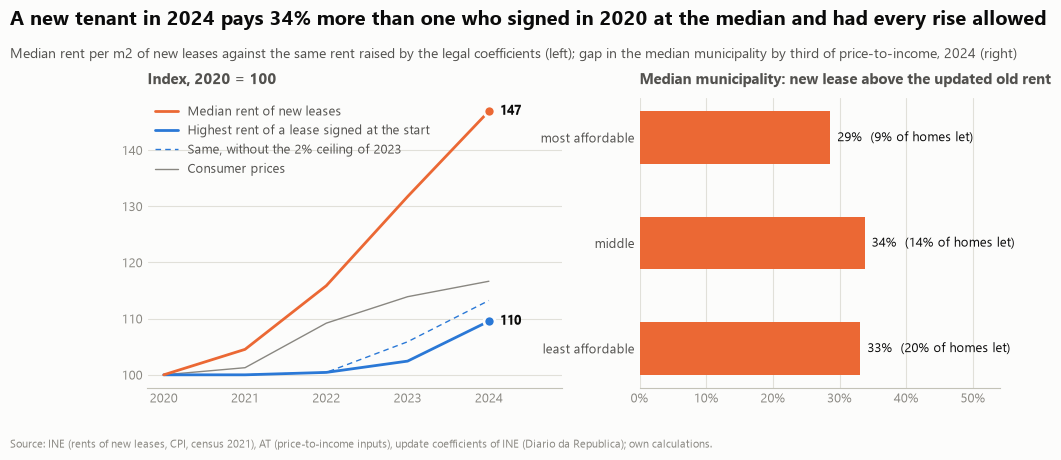

In [6]:
fig = charts.rent_update_gap(path, by_third)
style.save_fig(fig, "p3", "rent_update_gap")
fig

## Findings

1. **A sitting tenant's real rent fell, a new tenant's rose (RQ6.1, RQ6.3).** A lease signed at the 2020 median could be raised by
   9.5% by 2024 (coefficients 1, 1.0043, 1.02, 1.0694; 2021's 0.9997 counts as no rise), against consumer prices +16.7%: a fall of 6.1%
   in real terms. The median rent of new leases, over the 191 municipalities that publish both years, rose 46.9%, so a new tenant
   pays 34% more. The 2023 ceiling cut that year's allowed rise from 5.43% to 2.00% and the four-year rise from 13.2% to 9.5%.
2. **The gap is general and does not shrink where renting is common.** In the median of the same 191 municipalities a new lease in 2024
   costs 32% more than the 2020 median rent raised by every allowed update (98% have a positive gap; middle half 26% to 38%). Rank
   correlation of the gap with the share of homes let -0.04: no sign that a larger rental market narrows it. It is slightly larger in
   dearer places (0.24 with price-to-income; 29% in the most affordable third, 34% and 33% in the other two).
3. **Most of the let stock is not repriced in a year.** New leases of 2021 are 10 per 100 homes let in the 2021 census in the median
   of 187 municipalities (11.5, 10.4 and 9.5 by third, most affordable first), so roughly nine in ten let homes keep a rent bounded
   by the coefficients; that count is an upper bound of repricing (renewals and other regimes are not told apart). Those who move meet
   the market, so the gap matters for access, not only for who pays what.
4. **The 2023 ceiling was worth about 10 EUR a month to a typical lease.** At the 2022 median rent per m2 and an assumed 70 m2 let home
   (300 EUR a month before the update) it saved 10 EUR a month (3.4% of the rent), 7 at 50 m2 and 13 at 90 m2; at most 114 EUR m a year
   (81 to 146) if all 923,000 let homes had been updated at the ceiling. The law covers leases before 2022; landlords were compensated
   through IRS and IRC, so part of the cost moved to the state budget (not estimated).

**Reading rule:** the median gap (32%) is above 10% and does not fall with the share let, so the data read as a dual market, with sitting
tenants protected by the coefficient and new tenants exposed to the market.

**Limits.** Medians of new leases in the 191 municipalities that publish both years (selection towards towns with a rental market; the
national median over all places that published each year would have shown +39.7%, so composition matters), not the rents of the same
leases: size and quality of new leases change, so part of the gap is not a like-for-like price. The coefficient is a ceiling and the
update is optional; the median lease may have been raised less, or not at all; leases under older regimes (before 1990) and rents fixed by
other rules are not told apart. The area of a let home is an assumption, so the euro figures scale with it. No effect of the rule on
rental supply, maintenance, new building or conversion (RQ6.2) can be read from these data, and the gap would also open without the rule
if market rents outpaced prices; no comparison group. The 2023 ceiling (Lei 19/2022) and its 5.43% formula value are confirmed by
several press and professional sources; the coefficients are transcribed from published notices and compilations (see the file's `note`
column), and the notices themselves were not opened.